In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn_profile = pd.read_csv("../_supernova/results/sn_profile.csv")
bao_profile = pd.read_csv("../_bao/results/bao_profile.csv")

bao = pd.read_csv("../_bao/processed/bao.csv")
cov = np.load("../_bao/processed/bao_covariance.npz")["covariance"]

omega_m = sn_profile["Omega_m"].values
sn_chi2 = sn_profile["chi2"].values

assert np.allclose(omega_m, bao_profile["Omega_m"])
assert cov.shape == (len(bao), len(bao))

z = bao["z"].values
y = bao["value"].values
quantity = bao["quantity"].values

h0rd_grid = np.linspace(8000, 12000, 801)

In [2]:
z_grid = np.linspace(0, max(z), 4001)
dz = z_grid[1] - z_grid[0]

shape = np.zeros((len(bao), len(omega_m)))

for j, om in enumerate(omega_m):
    inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum(
        (inv_e[:-1] + inv_e[1:]) * dz / 2
    )

    dm = np.interp(z, z_grid, integral)
    dh = 1 / (om * (1 + z)**3 + 1 - om)**0.5
    dv = (z * dm**2 * dh)**(1 / 3)

    shape[quantity == "DM_over_rs", j] = dm[quantity == "DM_over_rs"]
    shape[quantity == "DH_over_rs", j] = dh[quantity == "DH_over_rs"]
    shape[quantity == "DV_over_rs", j] = dv[quantity == "DV_over_rs"]

In [3]:
white = np.linalg.solve(
    np.linalg.cholesky(cov),
    np.column_stack((y, shape)),
)

y_white = white[:, 0]
templates = white[:, 1:]

q = np.sum(templates**2, axis=0)
a_best = (y_white @ templates) / q

residual = y_white.reshape(-1, 1) - templates * a_best
bao_min_chi2 = np.sum(residual**2, axis=0)

assert np.allclose(
    bao_min_chi2,
    bao_profile["chi2"].values,
    rtol=0,
    atol=1e-5,
)

In [4]:
a_grid = 299792.458 / h0rd_grid

bao_surface = (
    bao_min_chi2.reshape(-1, 1)
    + q.reshape(-1, 1)
    * (a_grid - a_best.reshape(-1, 1))**2
)

joint_surface = bao_surface + sn_chi2.reshape(-1, 1)

np.savez_compressed(
    "results/h0rd_grid.npz",
    Omega_m=omega_m,
    H0rd=h0rd_grid,
    bao_chi2=bao_surface,
    joint_chi2=joint_surface,
)

In [5]:
def profile_interval(grid, chi2):
    best = np.argmin(chi2)
    delta = chi2 - chi2[best]

    lower = np.nan
    upper = np.nan

    if best > 0 and delta[0] > 1:
        lower = np.interp(
            1, delta[:best + 1][::-1], grid[:best + 1][::-1]
        )

    if best < len(grid) - 1 and delta[-1] > 1:
        upper = np.interp(
            1, delta[best:], grid[best:]
        )

    return lower, upper


rows = []

for name, surface in [
    ("BAO", bao_surface),
    ("SN + BAO", joint_surface),
]:
    best = np.argmin(surface)
    i = best // len(h0rd_grid)
    j = best % len(h0rd_grid)

    omega_profile = np.min(surface, axis=1)
    h0rd_profile = np.min(surface, axis=0)

    om_low, om_high = profile_interval(omega_m, omega_profile)
    h_low, h_high = profile_interval(h0rd_grid, h0rd_profile)

    rows.append({
        "data": name,
        "Omega_m": omega_m[i],
        "Omega_m_lower_68": om_low,
        "Omega_m_upper_68": om_high,
        "H0rd": h0rd_grid[j],
        "H0rd_lower_68": h_low,
        "H0rd_upper_68": h_high,
        "H0rd_error_minus": h0rd_grid[j] - h_low,
        "H0rd_error_plus": h_high - h0rd_grid[j],
        "chi2": surface[i, j],
    })

summary = pd.DataFrame(rows)
summary.to_csv("results/h0rd_summary.csv", index=False)

summary

,data,Omega_m,Omega_m_lower_68,Omega_m_upper_68,H0rd,H0rd_lower_68,H0rd_upper_68,H0rd_error_minus,H0rd_error_plus,chi2
0,BAO,0.298,0.288984,0.306202,10150.0,10080.705520,10227.376767,69.294480,77.376767,10.275038
1,SN + BAO,0.304,0.296382,0.312253,10105.0,10034.353134,10168.680404,70.646866,63.680404,1416.145863


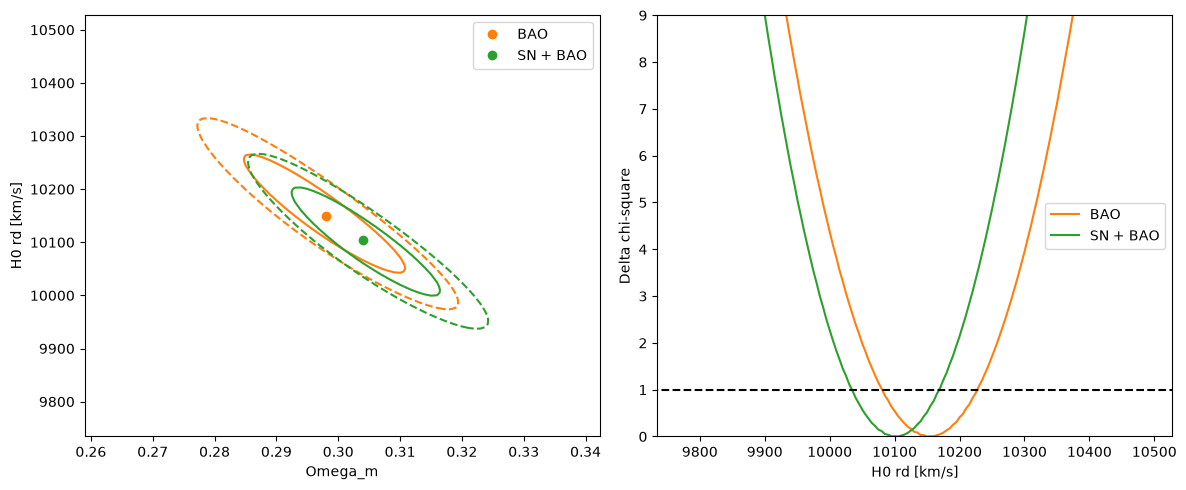

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

for name, surface, color in [
    ("BAO", bao_surface, "tab:orange"),
    ("SN + BAO", joint_surface, "tab:green"),
]:
    delta = surface - np.min(surface)

    plt.contour(
        omega_m,
        h0rd_grid,
        delta.T,
        levels=[2.30, 5.99],
        colors=[color],
        linestyles=["solid", "dashed"],
    )

    best = np.argmin(surface)
    i = best // len(h0rd_grid)
    j = best % len(h0rd_grid)

    plt.plot(
        omega_m[i], h0rd_grid[j],
        "o", color=color, label=name,
    )

plt.xlim(
    min(summary["Omega_m_lower_68"]) - 0.03,
    max(summary["Omega_m_upper_68"]) + 0.03,
)
plt.ylim(
    min(summary["H0rd_lower_68"]) - 300,
    max(summary["H0rd_upper_68"]) + 300,
)
plt.xlabel("Omega_m")
plt.ylabel("H0 rd [km/s]")
plt.legend()

plt.subplot(1, 2, 2)

for name, surface, color in [
    ("BAO", bao_surface, "tab:orange"),
    ("SN + BAO", joint_surface, "tab:green"),
]:
    curve = np.min(surface, axis=0)
    plt.plot(
        h0rd_grid,
        curve - min(curve),
        color=color,
        label=name,
    )

plt.plot([h0rd_grid[0], h0rd_grid[-1]], [1, 1], "k--")
plt.xlim(
    min(summary["H0rd_lower_68"]) - 300,
    max(summary["H0rd_upper_68"]) + 300,
)
plt.ylim(0, 9)
plt.xlabel("H0 rd [km/s]")
plt.ylabel("Delta chi-square")
plt.legend()

plt.tight_layout()
plt.savefig("results/h0rd_comparison.png", dpi=200)
plt.show()

In [7]:
width = summary["H0rd_upper_68"] - summary["H0rd_lower_68"]

precision = pd.DataFrame({
    "BAO_width_68": [width.iloc[0]],
    "joint_width_68": [width.iloc[1]],
    "width_reduction_percent": [
        100 * (1 - width.iloc[1] / width.iloc[0])
    ],
})

precision.to_csv("results/h0rd_precision.csv", index=False)

precision

,BAO_width_68,joint_width_68,width_reduction_percent
0,146.671247,134.32727,8.416085
